# 12 — El clima completo

## Qué contesta este cuaderno

El propietario siente que **el clima de Manizales se ha desaprovechado**: hasta ahora se usaron 4-5
variables de nivel. Pide **variables generales que afecten a toda la ciudad**, **horizonte largo**
(por ejemplo, **la sequía que está terminando ahora**) y le preocupa el **sobreajuste**
(`docs/CONTEXTO.md`, 2026-09-30, «Cambio de enfoque»).

El método se escribió **antes de mirar** en `patrones/datos/variables.csv`, filas `barrido_clima`,
`indices_generales` y `fin_de_sequia`, y aquí se aplica tal cual:

1. **Inventario** de todo lo que hay: el consenso y las tres fuentes crudas.
2. **Todas las variables** en cuatro formas: nivel, anomalía contra el mes, cambio a 1, 2 y 4 semanas,
   y extremos. Además, la **temporada**: lluvia acumulada de 4 y 8 semanas y su giro.
3. **Barrido** contra el triage semanal con rezagos de 0 a 8 semanas en **descubrir** (2022-03 a
   2024-12), con **Benjamini-Hochberg q = 0,10** sobre toda la familia.
4. **Confirmación** de cada superviviente en **confirmar** (2025-01 a 2026-08), con el mismo signo y
   el mismo rezago. **Solo cuenta lo confirmado.**
5. **Estados del clima**: componentes principales ajustados solo en descubrir.
6. Los mismos índices contra los **desenlaces secundarios** (respiratorio, infecciosas, trauma).
7. **El estado de hoy** y lo que hicieron episodios parecidos. Descriptivo, no pronóstico.
8. **Qué entra al repertorio.**

**El desenlace** es el de `notebooks/desenlace.py`: log del triage semanal **sin calendario y sin los
cortes de nivel de la red de salud** (Nueva EPS), **con** la estacionalidad, porque el clima puede
explicarla. Semanas epidemiológicas de domingo a sábado.

## De dónde salen los datos

| Qué | Archivo | Fuente |
|---|---|---|
| Clima diario unificado (consenso de cuatro fuentes, pluviómetro roto ya quitado) | `calendarios/clima_unificado.csv.gz` | IDEAM, METAR La Nubia, NASA POWER, Open-Meteo |
| METAR del aeropuerto La Nubia | `calendarios/clima/raw_iem_skmz.csv` | Iowa Environmental Mesonet |
| Reanálisis MERRA-2 y satélite, celda de ~55 km | `calendarios/clima/raw_nasapower.csv` | NASA POWER |
| Reanálisis ERA5-Land / ERA5 | `calendarios/clima/raw_openmeteo.csv` | Open-Meteo |
| Estaciones IDEAM empalmadas | `calendarios/clima/clima_ideam.csv` | IDEAM |
| Triage semanal y series de diagnóstico | `salidas/triage_diario.parquet`, `salidas/perfil_dx_diario.parquet` vía `notebooks/desenlace.py` | agregados del hospital, sin dato personal |

Cómo se construyó el consenso y por qué: `calendarios/docs/CLIMA.md`. **No hay conexión a la base del
hospital en este cuaderno.**

In [1]:
import sys, pathlib, warnings, os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")   # silencia un aviso de scikit-learn en Windows
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "notebooks")); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from matplotlib import pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from sklearn.decomposition import PCA
from desenlace import desenlace_semanal

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
CATEG = [AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO]
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
DIVERGENTE = LinearSegmentedColormap.from_list("div", [AZUL, "#f0efec", ROJO])
SECUENCIAL = LinearSegmentedColormap.from_list("sec", ["#f0efec", AZUL])
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 120)

DESC = ("2022-03-06", "2024-12-29")      # descubrir (el de desenlace.py)
CONF = ("2025-01-05", "2026-08-23")      # confirmar: el clima termina el 2026-08-28
CLIMA_REF = ("2020-01-01", "2024-12-31") # climatologia y percentiles: nunca con datos de confirmar
REZAGOS = range(0, 9)
Q_BH = 0.10

def a_semana(s, como="mean", minimo=6):
    """Semana epidemiologica (domingo a sabado), indexada por el domingo. Nula si faltan dias."""
    g = s.resample("W-SAT"); r = getattr(g, como)(); n = g.count()
    r = r.where(n >= minimo); r.index = r.index - pd.Timedelta(days=6)
    return r

def pct(b): return 100 * (np.exp(b) - 1)

cl = pd.read_csv(RAIZ / "calendarios/clima_unificado.csv.gz", parse_dates=["fecha"]).set_index("fecha").asfreq("D")
Y = desenlace_semanal()
print(f"clima: {cl.index.min():%Y-%m-%d} a {cl.index.max():%Y-%m-%d}, {len(cl)} días, {cl.shape[1]} columnas")
print(f"desenlace: {Y.index.min():%Y-%m-%d} a {Y.index.max():%Y-%m-%d}; semanas con y -> descubrir {Y.y.loc[DESC[0]:DESC[1]].notna().sum()}, "
      f"confirmar {Y.y.loc[CONF[0]:CONF[1]].notna().sum()}; secundarios: {[c for c in Y if c.startswith('y_')]}")

clima: 2020-01-01 a 2026-08-28, 2432 días, 68 columnas
desenlace: 2022-03-06 a 2026-09-13; semanas con y -> descubrir 147, confirmar 86; secundarios: ['y_respiratorio', 'y_infecciosas', 'y_trauma']


---
# 1. Inventario: qué clima hay

Cada fila es una variable de una fuente: cobertura entre el 2020-01-01 y el 2026-08-28 y qué papel
tiene en el consenso. Después, la calidad de la lluvia, que es lo delicado: cada fuente se compara
con el pluviómetro **solo en los días en que el pluviómetro es válido**.

In [2]:
periodo = pd.date_range("2020-01-01", "2026-08-28")
leer = lambda n: pd.read_csv(RAIZ / f"calendarios/clima/{n}", parse_dates=["fecha"]).drop_duplicates("fecha").set_index("fecha").reindex(periodo)
iem, nasa, om, ideam = leer("raw_iem_skmz.csv"), leer("raw_nasapower.csv"), leer("raw_openmeteo.csv"), leer("clima_ideam.csv")
def fila(fuente, variable, s, uso):
    s = s.reindex(periodo)
    return {"fuente": fuente, "variable": variable, "desde": f"{s.first_valid_index():%Y-%m}" if s.notna().any() else "—",
            "hasta": f"{s.last_valid_index():%Y-%m}" if s.notna().any() else "—", "% días": round(100 * s.notna().mean(), 1), "uso en el consenso": uso}
pluvio = cl.precipitacion_mm.where(cl.precip_con_estacion & ~cl.pluviometro_fallido)
inv = pd.DataFrame([
    fila("IDEAM (3 estaciones)", "lluvia de pluviómetro válida", pluvio, "referencia de lluvia"),
    fila("IDEAM (3 estaciones)", "temperatura media (hasta 24 lecturas/día)", ideam.temp_media.where(ideam.estacion_clima.ne("PLANALTO")), "referencia de la media (sin Planalto)"),
    fila("METAR La Nubia (IEM)", "temperatura máxima y mínima", iem.iem_tmax_c, "referencia de máx. y mín."),
    fila("METAR La Nubia (IEM)", "humedad relativa mín. y máx.", iem.iem_hr_min, "fuente secundaria"),
    fila("METAR La Nubia (IEM)", "punto de rocío máx. y mín.", iem.max_dwpf, "no entra"),
    fila("METAR La Nubia (IEM)", "viento medio", iem.avg_sknt, "referencia del viento"),
    fila("METAR La Nubia (IEM)", "sensación térmica", iem.avg_feel, "no entra (función de temp. y viento)"),
    fila("METAR La Nubia (IEM)", "lluvia", iem.precip, "vacía"),
    fila("NASA POWER (~55 km)", "temperatura media, máx. y mín.", nasa.np_T2M, "fuente secundaria"),
    fila("NASA POWER (~55 km)", "humedad relativa media", nasa.np_RH2M, "referencia de humedad"),
    fila("NASA POWER (~55 km)", "punto de rocío medio", nasa.np_T2MDEW, "no hay consenso: se usa tal cual"),
    fila("NASA POWER (~55 km)", "lluvia", nasa.np_PRECTOTCORR, "relleno escalado donde falta el pluviómetro"),
    fila("NASA POWER (~55 km)", "viento a 2 m", nasa.np_WS2M, "fuente secundaria"),
    fila("NASA POWER (~55 km)", "radiación solar", nasa.np_ALLSKY_SFC_SW_DWN, "única fuente real de la radiación"),
    fila("Open-Meteo (ERA5-Land)", "temperatura media, máx. y mín.", om.om_temperature_2m_mean, "fuente secundaria"),
    fila("Open-Meteo (ERA5-Land)", "humedad relativa media", om.om_relative_humidity_2m_mean, "fuente secundaria"),
    fila("Open-Meteo (ERA5, ~28 km)", "lluvia", om.om_precipitation_sum, "excluida (ver tabla de lluvia)"),
    fila("Open-Meteo (ERA5, ~28 km)", "horas de lluvia", om.om_precipitation_hours, "no entra al consenso"),
    fila("Open-Meteo", "viento, radiación, evapotranspiración", om.om_wind_speed_10m_max, "columnas vacías"),
])
print("radiación del consenso = NASA POWER exactamente:", bool((cl.radiacion_consenso - cl.np_ALLSKY_SFC_SW_DWN).abs().max() == 0))
inv

radiación del consenso = NASA POWER exactamente: True


,fuente,variable,desde,hasta,% días,uso en el consenso
0,IDEAM (3 estaciones),lluvia de pluviómetro válida,2020-01,2026-08,34.7,referencia de lluvia
1,IDEAM (3 estaciones),temperatura media (hasta 24 lecturas/día),2020-01,2026-08,46.4,referencia de la media (sin Planalto)
2,METAR La Nubia (IEM),temperatura máxima y mínima,2020-01,2026-08,82.9,referencia de máx. y mín.
3,METAR La Nubia (IEM),humedad relativa mín. y máx.,2020-01,2026-08,83.0,fuente secundaria
4,METAR La Nubia (IEM),punto de rocío máx. y mín.,2020-01,2026-08,83.0,no entra
5,METAR La Nubia (IEM),viento medio,2020-01,2026-08,75.0,referencia del viento
6,METAR La Nubia (IEM),sensación térmica,2020-01,2026-08,77.5,no entra (función de temp. y viento)
7,METAR La Nubia (IEM),lluvia,—,—,0.0,vacía
8,NASA POWER (~55 km),"temperatura media, máx. y mín.",2020-01,2026-08,99.8,fuente secundaria
9,NASA POWER (~55 km),humedad relativa media,2020-01,2026-08,99.8,referencia de humedad


In [3]:
# ---- ¿Qué fuente de lluvia se parece al pluviómetro? Solo días con pluviómetro válido.
v = pluvio.notna()
fuentes = {"pluviómetro IDEAM": cl.precipitacion_mm, "NASA POWER": cl.np_PRECTOTCORR, "Open-Meteo, lluvia": cl.om_precipitation_sum,
           "Open-Meteo, horas de lluvia": cl.om_precipitation_hours, "consenso": cl.precip_consenso_mm}
semana_valida = a_semana(v.astype(float), "sum", 1) == 7
filas = []
for nom, s in fuentes.items():
    d = s[v]; w = a_semana(s.where(v), "sum", 7)[semana_valida]; wp = a_semana(pluvio, "sum", 7)[semana_valida]
    es_h = "horas" in nom
    filas.append({"fuente": nom, "media anual (mm)": None if es_h else round(365 * d.mean()),
                  "% días ≥ 1 mm": None if es_h else round(100 * (d >= 1).mean(), 1),
                  "horas/día (mediana)": round(d.median(), 1) if es_h else None,
                  "r diario con pluviómetro": round(d.corr(pluvio[v]), 2), "r semanal con pluviómetro": round(w.corr(wp), 2)})
print(f"{int(v.sum())} días con pluviómetro válido; {int(semana_valida.sum())} semanas completas con pluviómetro")
display(pd.DataFrame(filas).set_index("fuente"))
# ---- la racha seca se mide con el consenso: ¿los días secos dependen de la fuente del día?
seco = (cl.precip_consenso_mm < 1)
t = seco.groupby([cl.index.year, np.where(v, "con pluviómetro", "sin pluviómetro (NASA escalado)")]).mean().unstack().mul(100).round(1)
t.index.name = "% de días secos (< 1 mm) en el consenso"
t

844 días con pluviómetro válido; 77 semanas completas con pluviómetro


,media anual (mm),% días ≥ 1 mm,horas/día (mediana),r diario con pluviómetro,r semanal con pluviómetro
fuente,,,,,
pluviómetro IDEAM,1352.0,43.0,NaN,1.00,1.00
NASA POWER,1969.0,78.6,NaN,0.30,0.46
"Open-Meteo, lluvia",16621.0,97.6,NaN,-0.02,0.01
"Open-Meteo, horas de lluvia",NaN,NaN,24.0,0.06,0.18
consenso,1352.0,66.0,NaN,0.90,0.92


,con pluviómetro,sin pluviómetro (NASA escalado)
% de días secos (< 1 mm) en el consenso,,
2020,43.6,49.8
2021,NaN,54.8
2022,22.1,19.1
2023,33.3,34.8
2024,36.4,34.4
2025,32.6,14.9
2026,45.5,24.6


## Lectura

**Hay mucho menos clima independiente del que parece.** De las 68 columnas del archivo unificado, las
medidas en tierra son pocas y cubren poco:

| Medida en tierra | % de días |
|---|---|
| Lluvia de pluviómetro válida | **34,7** |
| Temperatura media IDEAM (sin Planalto) | 46,4 |
| Máxima y mínima del METAR | 82,9 |
| Viento del METAR | 75,0 |

El resto es reanálisis: NASA POWER cubre el 99,8 % y Open-Meteo el 99,3 %. **La radiación del
consenso es NASA POWER exactamente**: Open-Meteo trae vacías la radiación, el viento y la
evapotranspiración. El METAR no trae lluvia.

**La calidad de la lluvia**, en los 844 días con pluviómetro válido:

| Fuente | mm/año | % días ≥ 1 mm | r diario | r semanal |
|---|---|---|---|---|
| Pluviómetro IDEAM | 1.352 | 43,0 | 1 | 1 |
| NASA POWER | 1.969 | 78,6 | 0,30 | 0,46 |
| Open-Meteo, lluvia | 16.621 | 97,6 | −0,02 | 0,01 |
| Open-Meteo, horas de lluvia | mediana 24 h/día | — | 0,06 | 0,18 |
| Consenso | 1.352 | **66,0** | 0,90 | 0,92 |

- **Las horas de lluvia de Open-Meteo no sirven**: la mediana es de 24 horas al día y la correlación
  semanal con el pluviómetro es 0,18. Entran al barrido porque así se preregistró, pero **quedan
  fuera de los índices** (sección 5). Es una decisión por calidad, tomada antes de mirar el triage.
- **La lluvia de Open-Meteo es ruido**, como ya decía `CLIMA.md`.
- **Hallazgo nuevo: el consenso llueve más días que el pluviómetro, incluso donde hay
  pluviómetro.** En esos días acierta el total (1.352 mm, r semanal 0,92), pero marca lluvia el
  66,0 % de los días cuando el pluviómetro la marca el 43,0 %. La mediana de dos fuentes promedia el
  pluviómetro con la llovizna de NASA. **Consecuencia: el consenso tiene menos días secos que la
  realidad, y la racha seca sale más corta.**
- **Los días secos del consenso dependen de la fuente del día.** En 2025 son el 32,6 % con
  pluviómetro y el 14,9 % sin él; en 2026, el 45,5 % y el 24,6 %. **La racha seca es la variable
  menos fiable del barrido.** Por eso la lluvia se usa en acumulados semanales y de 4 y 8 semanas,
  donde el total sí es robusto.
- **2021 no tiene ni un día con pluviómetro.** No entra en las pruebas: descubrir empieza en 2022-03,
  y el rezago máximo de 8 semanas llega a enero de 2022.

---
# 2. Las variables derivadas, por semana

**Once variables base**, del consenso salvo donde no lo hay:
- temperatura media, máxima y mínima;
- amplitud térmica (máxima − mínima);
- humedad;
- punto de rocío (NASA POWER);
- lluvia (suma de la semana, es decir, un acumulado de 7 días);
- horas de lluvia (Open-Meteo);
- viento;
- radiación (NASA POWER);
- **racha seca**: días seguidos con < 1 mm al cierre de la semana, que puede pasar de 7.

**Cada una en cinco formas:**
- el nivel;
- la anomalía contra lo normal de ese mes;
- el cambio a 1, 2 y 4 semanas.

**Extremos:** los días de la semana por encima del p90 o por debajo del p10 **de su mes**. Para la
lluvia, días > p90 y días secos (< 1 mm), porque su p10 es cero.

**La temporada** (`fin_de_sequia`): lluvia de 4 y 8 semanas en % sobre lo normal para el mes, y su
giro. El giro es el cambio frente a 4 u 8 semanas antes, en puntos porcentuales.

**La climatología y los percentiles salen solo de 2020-2024**, así que el periodo de confirmar nunca
se usa para definir lo «normal».

In [4]:
dia = cl.loc["2020-01-01":"2026-08-28"]
diarias = pd.DataFrame({
    "temp. media": dia.temp_media_consenso, "temp. máxima": dia.temp_max_consenso, "temp. mínima": dia.temp_min_consenso,
    "amplitud térmica": dia.temp_max_consenso - dia.temp_min_consenso, "humedad": dia.humedad_consenso,
    "punto de rocío": dia.np_T2MDEW, "lluvia": dia.precip_consenso_mm, "horas de lluvia": dia.om_precipitation_hours,
    "viento": dia.viento_consenso_ms, "radiación": dia.radiacion_consenso})
seco_d = (diarias.lluvia < 1).astype(float)
racha_d = seco_d.groupby((seco_d != 1).cumsum()).cumsum().where(diarias.lluvia.notna())   # días seguidos con < 1 mm

SEM = pd.date_range("2020-01-05", "2026-09-13", freq="W-SUN")
nivel = pd.DataFrame({c: a_semana(diarias[c], "sum" if c == "lluvia" else "mean", 7 if c == "lluvia" else 6)
                      for c in diarias}).reindex(SEM)
nivel["racha seca"] = a_semana(racha_d, "last", 1).reindex(SEM)          # al cierre de la semana; puede pasar de 7
mes = pd.Series((SEM + pd.Timedelta(days=3)).month, index=SEM)          # el mes de la mitad de la semana
ref = (SEM >= CLIMA_REF[0]) & (SEM <= CLIMA_REF[1])
clim = nivel[ref].groupby(mes[ref]).mean()
anom = nivel - clim.reindex(mes.values).values

# extremos: días de la semana por encima del p90 (o por debajo del p10) de su mes, percentiles de 2020-2024
ref_d = diarias.loc[CLIMA_REF[0]:CLIMA_REF[1]]
p90 = ref_d.groupby(ref_d.index.month).quantile(.9).reindex(diarias.index.month).set_axis(diarias.index)
p10 = ref_d.groupby(ref_d.index.month).quantile(.1).reindex(diarias.index.month).set_axis(diarias.index)
dias_sem = lambda b: (7 * a_semana(b.astype(float).where(diarias[b.name].notna()), "mean", 6)).reindex(SEM)

X = {}
for c in nivel:
    X[(c, "nivel")] = nivel[c]; X[(c, "anomalía")] = anom[c]
    for k in (1, 2, 4): X[(c, f"cambio {k} sem")] = nivel[c].diff(k)
for c in ["temp. media", "temp. máxima", "temp. mínima", "amplitud térmica", "humedad", "punto de rocío", "viento", "radiación"]:
    X[(c, "días > p90")] = dias_sem((diarias[c] > p90[c]).rename(c))
    X[(c, "días < p10")] = dias_sem((diarias[c] < p10[c]).rename(c))
X[("lluvia", "días > p90")] = dias_sem((diarias.lluvia > p90.lluvia).rename("lluvia"))
X[("lluvia", "días secos")] = dias_sem((diarias.lluvia < 1).rename("lluvia"))

# temporada: lluvia acumulada de 4 y 8 semanas en % sobre lo normal para ese mes, y su giro (fin_de_sequia)
TEMP = pd.DataFrame(index=SEM)
for k in (4, 8):
    acum = nivel.lluvia.rolling(k).sum()
    normal = acum[ref].groupby(mes[ref]).mean()
    TEMP[f"lluvia {k} sem (% sobre lo normal)"] = 100 * (acum / normal.reindex(mes.values).values - 1)
TEMP["giro 4 sem (pp)"] = TEMP["lluvia 4 sem (% sobre lo normal)"].diff(4)
TEMP["giro 8 sem (pp)"] = TEMP["lluvia 8 sem (% sobre lo normal)"].diff(8)
for c in TEMP: X[("temporada", c)] = TEMP[c]
X = pd.DataFrame(X)
X.loc["2026-08-30":] = np.nan                                          # no hay clima después del 2026-08-28
print(f"{nivel.shape[1]} variables base; {X.shape[1]} variables derivadas; x {len(REZAGOS)} rezagos = {X.shape[1] * len(REZAGOS)} pruebas")
print("cobertura en descubrir+confirmar (% semanas con dato), la más baja:",
      X.loc["2021-12-26":CONF[1]].notna().mean().mul(100).round(1).nsmallest(4).to_dict())
X.columns.get_level_values(1).value_counts().rename("variables por forma").to_frame().T

11 variables base; 77 variables derivadas; x 9 rezagos = 693 pruebas
cobertura en descubrir+confirmar (% semanas con dato), la más baja: {('temp. media', 'nivel'): 99.6, ('temp. media', 'anomalía'): 99.6, ('temp. media', 'cambio 1 sem'): 99.6, ('temp. media', 'cambio 2 sem'): 99.6}


,nivel,anomalía,cambio 1 sem,cambio 2 sem,cambio 4 sem,días > p90,días < p10,días secos,lluvia 4 sem (% sobre lo normal),lluvia 8 sem (% sobre lo normal),giro 4 sem (pp),giro 8 sem (pp)
variables por forma,11,11,11,11,11,9,8,1,1,1,1,1


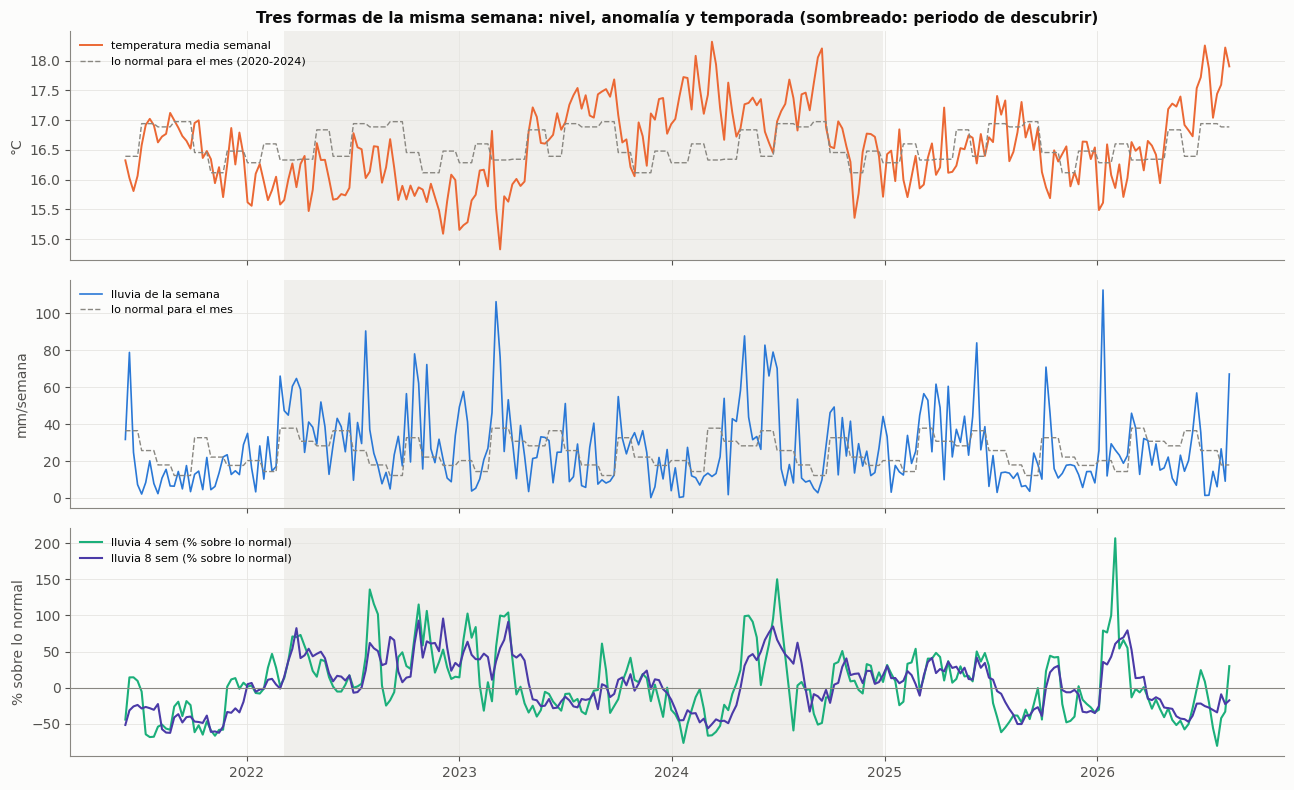

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
w = SEM[(SEM >= "2021-06-01")]
axes[0].plot(w, nivel.loc[w, "temp. media"], color=NARANJA, lw=1.4, label="temperatura media semanal")
axes[0].plot(w, (nivel["temp. media"] - anom["temp. media"]).loc[w], color=MUDO, lw=1, ls="--", label="lo normal para el mes (2020-2024)")
axes[0].set_ylabel("°C"); axes[0].legend(fontsize=8, loc="upper left")
axes[1].plot(w, nivel.loc[w, "lluvia"], color=AZUL, lw=1.2, label="lluvia de la semana")
axes[1].plot(w, (nivel.lluvia - anom.lluvia).loc[w], color=MUDO, lw=1, ls="--", label="lo normal para el mes")
axes[1].set_ylabel("mm/semana"); axes[1].legend(fontsize=8, loc="upper left")
for c, col in [("lluvia 4 sem (% sobre lo normal)", AQUA), ("lluvia 8 sem (% sobre lo normal)", VIOLETA)]:
    axes[2].plot(w, TEMP.loc[w, c], color=col, lw=1.5, label=c)
axes[2].axhline(0, color=MUDO, lw=.8); axes[2].set_ylabel("% sobre lo normal"); axes[2].legend(fontsize=8, loc="upper left")
for ax in axes:
    ax.axvspan(pd.Timestamp(DESC[0]), pd.Timestamp(DESC[1]), color="#f0efec", lw=0, zorder=0)
axes[0].set_title("Tres formas de la misma semana: nivel, anomalía y temporada (sombreado: periodo de descubrir)")
plt.tight_layout(); plt.show()

## Lectura

**77 variables derivadas × 9 rezagos = 693 pruebas.** Es la familia sobre la que se corrige por
comparaciones múltiples. La cobertura en 2022-2026 es alta: la variable más incompleta tiene el
99,6 % de las semanas.

La figura muestra por qué hacen falta las tres escalas:
- **La temperatura tiene épocas largas.** 2021 y el arranque de 2022 van fríos. La segunda mitad de
  2023 y buena parte de 2024 van por encima de lo normal, y **mediados de 2026 también**. Un nivel
  semanal mezcla la época con la semana.
- **La lluvia semanal es muy ruidosa.** Solo en 4 y 8 semanas aparecen las temporadas: las secas de
  2020-2021, la lluviosa de 2022, la seca de finales de 2023 y comienzos de 2024, el giro lluvioso
  de enero de 2026 y **la seca de 2026, que se corta en agosto**.

**Límite.** El «normal» de cada mes sale de solo cinco años (2020-2024), y la figura muestra que esos
años tuvieron épocas frías y cálidas largas. Una anomalía es relativa a ese quinquenio, no a un clima
de 30 años.

---
# 3. El barrido, en el periodo de descubrir

Para cada variable y cada rezago de 0 a 8 semanas: una regresión del desenlace sobre la variable,
con errores robustos a la autocorrelación (HAC, 4 rezagos). La variable va en desviaciones típicas
del periodo de descubrir, así que **el efecto se lee como «% de triage por 1 sd»**.

Después, **Benjamini-Hochberg con q = 0,10** sobre las 693 pruebas juntas.

In [6]:
def prueba(y, x, extra=None, maxlags=4):
    d = pd.concat([y.rename("y"), x.rename("x")] + ([extra] if extra is not None else []), axis=1).dropna()
    if len(d) < 30 or d.x.std() == 0: return dict(b=np.nan, se=np.nan, p=np.nan, n=len(d))
    Z = sm.add_constant(d.drop(columns="y"))
    m = sm.OLS(d.y, Z).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})
    return dict(b=m.params["x"], se=m.bse["x"], p=m.pvalues["x"], n=len(d))

SD = X.loc[DESC[0]:DESC[1]].std()                      # 1 unidad = 1 desviación típica del periodo de descubrir
Xs = X / SD
def barrer(Xs, y, periodo, rezagos=REZAGOS):
    y = y.loc[periodo[0]:periodo[1]]
    nombre = lambda c: c if isinstance(c, tuple) else (c, "índice")
    return pd.DataFrame([{"variable": nombre(c)[0], "forma": nombre(c)[1], "rezago": k, **prueba(y, Xs[c].shift(k))}
                         for c in Xs.columns for k in rezagos])
B = barrer(Xs, Y.y, DESC)
B["efecto %"] = pct(B.b)
B["sobrevive BH"], B["q"], *_ = multipletests(B.p.fillna(1), alpha=Q_BH, method="fdr_bh")
S = B[B["sobrevive BH"]].copy()
print(f"pruebas: {len(B)} (válidas {B.p.notna().sum()}); p < 0,05 sin corregir: {(B.p < .05).sum()} "
      f"(el azar solo daría ~{round(.05 * B.p.notna().sum())}); sobreviven a BH q = {Q_BH}: {len(S)} pruebas, "
      f"{S[['variable', 'forma']].drop_duplicates().shape[0]} variables derivadas, {S.variable.nunique()} variables base")
print("supervivientes por rezago (semanas):", S.rezago.value_counts().sort_index().to_dict(), "| por signo:", {"+": int((S.b > 0).sum()), "−": int((S.b < 0).sum())})
S.assign(IC95=[f"[{pct(b - 1.96 * s):+.1f}; {pct(b + 1.96 * s):+.1f}]" for b, s in zip(S.b, S.se)]) \
 [["variable", "forma", "rezago", "efecto %", "IC95", "p", "q", "n"]].sort_values("p").round({"efecto %": 1, "p": 5, "q": 4})

pruebas: 693 (válidas 693); p < 0,05 sin corregir: 84 (el azar solo daría ~35); sobreviven a BH q = 0.1: 34 pruebas, 26 variables derivadas, 10 variables base
supervivientes por rezago (semanas): {0: 22, 1: 2, 2: 1, 3: 1, 4: 1, 5: 4, 6: 2, 8: 1} | por signo: {'+': 24, '−': 10}


,variable,forma,rezago,efecto %,IC95,p,q,n
558,amplitud térmica,días < p10,0,-2.0,[-2.8; -1.3],0.00000,0.0000,147
441,radiación,cambio 4 sem,0,2.1,[+1.2; +3.1],0.00001,0.0040,147
144,amplitud térmica,anomalía,0,1.9,[+1.0; +2.7],0.00002,0.0041,147
93,temp. mínima,nivel,3,1.9,[+0.9; +2.9],0.00011,0.0194,147
27,temp. media,cambio 2 sem,0,1.6,[+0.7; +2.4],0.00028,0.0300,147
567,humedad,días > p90,0,-1.5,[-2.3; -0.7],0.00030,0.0300,147
630,radiación,días < p10,0,-1.5,[-2.3; -0.7],0.00030,0.0300,147
180,humedad,nivel,0,-1.6,[-2.5; -0.7],0.00042,0.0316,147
550,amplitud térmica,días > p90,1,1.3,[+0.6; +2.0],0.00042,0.0316,147
189,humedad,anomalía,0,-1.5,[-2.3; -0.7],0.00053,0.0316,147


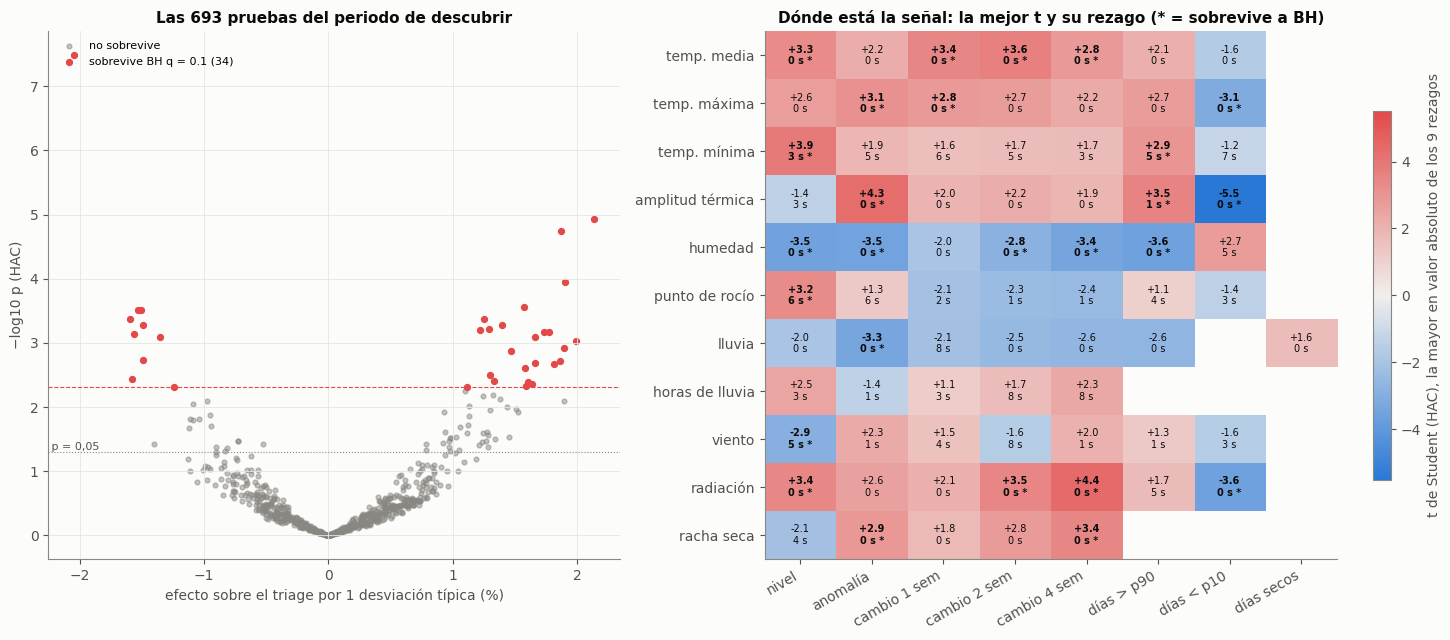

,0 sem,1 sem,2 sem,3 sem,4 sem,5 sem,6 sem,7 sem,8 sem
temporada: t por rezago,,,,,,,,,
giro 4 sem (pp),-1.4,0.3,-0.2,-0.6,-0.3,-0.9,0.1,1.6,1.2
giro 8 sem (pp),-0.6,-0.5,-0.0,0.5,0.7,0.6,0.8,0.6,0.4
lluvia 4 sem (% sobre lo normal),-2.3,-0.6,-0.5,-0.3,-0.1,-0.9,-0.3,0.4,0.2
lluvia 8 sem (% sobre lo normal),-1.8,-1.7,-0.8,-0.5,-0.3,-0.5,-0.5,-0.5,-0.6


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
umbral = B.loc[B["sobrevive BH"], "p"].max() if B["sobrevive BH"].any() else B.p.min() / 2
ax.scatter(B["efecto %"], -np.log10(B.p), s=12, color=MUDO, alpha=.5, label="no sobrevive")
ax.scatter(S["efecto %"], -np.log10(S.p), s=18, color=ROJO, label=f"sobrevive BH q = {Q_BH} ({len(S)})")
ax.axhline(-np.log10(umbral), color=ROJO, lw=.8, ls="--"); ax.axhline(-np.log10(.05), color=MUDO, lw=.8, ls=":")
ax.text(ax.get_xlim()[0], -np.log10(.05), " p = 0,05", va="bottom", fontsize=8, color=TINTA2)
ax.set_xlabel("efecto sobre el triage por 1 desviación típica (%)"); ax.set_ylabel("−log10 p (HAC)")
ax.set_title(f"Las {B.p.notna().sum()} pruebas del periodo de descubrir"); ax.legend(fontsize=8, loc="upper left")
# mapa: la mejor t de cada variable x forma (con signo) y su rezago
B["t"] = B.b / B.se
mejor = B.loc[B.groupby(["variable", "forma"]).t.apply(lambda s: s.abs().idxmax() if s.notna().any() else s.index[0])]
formas = ["nivel", "anomalía", "cambio 1 sem", "cambio 2 sem", "cambio 4 sem", "días > p90", "días < p10", "días secos"]
M = mejor.pivot(index="variable", columns="forma", values="t").reindex(columns=[f for f in formas if f in mejor.forma.values])
R = mejor.pivot(index="variable", columns="forma", values="rezago").reindex_like(M)
M = M.reindex([v for v in nivel.columns if v in M.index])
R = R.reindex(M.index)
ax = axes[1]; lim = np.nanmax(np.abs(M.values))
im = ax.imshow(M.values, cmap=DIVERGENTE, vmin=-lim, vmax=lim, aspect="auto")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        if np.isfinite(M.values[i, j]):
            ok = ((S.variable == M.index[i]) & (S.forma == M.columns[j])).any()
            ax.text(j, i, f"{M.values[i, j]:+.1f}\n{int(R.values[i, j])} s" + (" *" if ok else ""), ha="center", va="center", fontsize=7,
                    color=TINTA, fontweight="bold" if ok else "normal")
ax.set_xticks(range(M.shape[1]), M.columns, rotation=30, ha="right"); ax.set_yticks(range(M.shape[0]), M.index); ax.grid(False)
plt.colorbar(im, ax=ax, shrink=.7, label="t de Student (HAC), la mayor en valor absoluto de los 9 rezagos")
ax.set_title("Dónde está la señal: la mejor t y su rezago (* = sobrevive a BH)")
plt.tight_layout(); plt.show()
tt = B[B.variable.eq("temporada")].pivot(index="forma", columns="rezago", values="t").round(1)
tt.columns = [f"{k} sem" for k in tt.columns]; tt.index.name = "temporada: t por rezago"
tt

## Lectura

**En descubrir hay señal por encima del azar, pero pequeña y casi toda de la misma semana.**
- **84 pruebas dan p < 0,05**, cuando el azar solo daría ~35.
- **34 sobreviven a BH**: 26 variables derivadas de 10 variables base.
- **22 de las 34 están a rezago 0.** Solo 12 miran hacia atrás (1 a 8 semanas).

**El patrón es uno solo, visto desde muchas variables: las semanas soleadas, secas y cálidas traen
algo más de triage.** Las mayores:

| Variable | Rezago | Efecto por 1 sd | IC95 |
|---|---|---|---|
| Amplitud térmica, días < p10 (días nublados y parejos) | 0 | **−2,0 %** | [−2,8; −1,3] |
| Radiación, cambio a 4 semanas | 0 | **+2,1 %** | [+1,2; +3,1] |
| Amplitud térmica, anomalía | 0 | +1,9 % | [+1,0; +2,7] |
| Temperatura mínima, nivel | 3 | +1,9 % | [+0,9; +2,9] |
| Humedad, nivel | 0 | −1,6 % | [−2,5; −0,7] |
| Lluvia, anomalía | 0 | −1,4 % | [−2,1; −0,6] |

**El tamaño es de 1 a 2 % por desviación típica**, contra un ruido semanal del desenlace del 6 %. Es el
rango que publica la literatura (2 a 10 %), en su extremo bajo.

**La temporada no aparece.** Ninguna de las cuatro variables de `fin_de_sequia` sobrevive:
- la lluvia de 4 semanas llega a t = −2,3 a rezago 0;
- la de 8 semanas, a −1,8 a rezago 0;
- el giro de 4 semanas, a +1,6 a 7 semanas;
- el giro de 8 semanas no pasa de 0,8.

**En 2022-2024, el paso de seco a lluvioso a escala de temporada no se siguió de más triage total.**

**Límites.**
- Las variables están muy correlacionadas entre sí: la radiación, la amplitud, la humedad y la lluvia
  miden el mismo estado del cielo. **34 supervivientes no son 34 hallazgos**, son uno o dos.
- **Rezago 0 no sirve para predecir** sin un pronóstico del tiempo de esa misma semana.
- El desenlace conserva la estación, así que una variable de nivel puede estar haciendo de reloj del
  año.

---
# 4. Confirmación: ¿se repite en 2025-2026?

Cada una de las 34 pruebas supervivientes se repite **con la misma variable, la misma forma y el mismo
rezago** en 2025-01 a 2026-08, con la escala de descubrir.
- **Criterio fijado:** mismo signo y p < 0,05.
- **Criterio más exigente:** BH unilateral sobre las 34, en la dirección descubierta.

Para no confundir «no se repite» con «no hay datos para verlo», se calcula la **potencia**: la
probabilidad de confirmar si el efecto real fuera el de descubrir.

In [8]:
CF = pd.DataFrame([prueba(Y.y.loc[CONF[0]:CONF[1]], Xs[(r.variable, r.forma)].shift(r.rezago)) for r in S.itertuples()], index=S.index)
S = S.join(CF.add_suffix(" conf"))
S["efecto % conf"] = pct(S["b conf"])
S["mismo signo"] = np.sign(S.b) == np.sign(S["b conf"])
S["confirma (mismo signo, p < 0,05)"] = S["mismo signo"] & (S["p conf"] < .05)
from scipy.stats import norm
S["potencia"] = norm.cdf(S.b.abs() / S["se conf"] - 1.96)   # si el efecto real fuera el de descubrir
if len(S):
    S["confirma BH"] = multipletests(np.where(S["mismo signo"], S["p conf"] / 2, 1), alpha=Q_BH, method="fdr_bh")[0]  # unilateral en la dirección descubierta
print(f"sobreviven a BH en descubrir: {len(S)}; mismo signo en confirmar: {int(S['mismo signo'].sum())}; "
      f"confirman con p < 0,05: {int(S['confirma (mismo signo, p < 0,05)'].sum())}; confirman con BH unilateral q = {Q_BH} en la familia de confirmación: "
      f"{int(S['confirma BH'].sum()) if len(S) else 0}")
print(f"error típico mediano: descubrir {100 * S.se.median():.2f} pp, confirmar {100 * S['se conf'].median():.2f} pp; potencia mediana para "
      f"repetir el efecto descubierto: {S.potencia.median():.2f} -> se esperarían ~{S.potencia.sum():.0f} confirmaciones si todo fuera real "
      f"(sin descontar la maldición del ganador)")
print(f"si NADA fuera real, cada prueba confirma por azar con probabilidad 0,025 (mismo signo y p < 0,05): se esperarían {0.025 * len(S):.2f} de {len(S)}")
print(f"efecto en confirmar / efecto en descubrir, mediana: {(S['efecto % conf'] / S['efecto %']).median():.2f}")
print(f"días con pluviómetro válido: descubrir {100 * v.loc['2022-03-06':'2024-12-28'].mean():.1f} %, confirmar {100 * v.loc['2025-01-05':'2026-08-28'].mean():.1f} %")
C = S[S["confirma (mismo signo, p < 0,05)"]].copy()
# diagnóstico, no una prueba nueva: ¿el efecto confirmado sigue con el mes del año fijo? (¿clima o estación?)
todo = (DESC[0], CONF[1])
mes_d = pd.get_dummies(pd.Series(((Y.index + pd.Timedelta(days=3)).month), index=Y.index), prefix="m", drop_first=True).astype(float)
C["efecto % con mes fijo 2022-26"] = [pct(prueba(Y.y.loc[todo[0]:todo[1]], Xs[(r.variable, r.forma)].shift(r.rezago), mes_d)["b"]) for r in C.itertuples()]
C["p con mes fijo"] = [prueba(Y.y.loc[todo[0]:todo[1]], Xs[(r.variable, r.forma)].shift(r.rezago), mes_d)["p"] for r in C.itertuples()]
S[["variable", "forma", "rezago", "efecto %", "p", "efecto % conf", "p conf", "potencia", "mismo signo", "confirma (mismo signo, p < 0,05)"]] \
  .sort_values(["confirma (mismo signo, p < 0,05)", "p conf"], ascending=[False, True]).round({"efecto %": 1, "efecto % conf": 1, "p": 5, "p conf": 4, "potencia": 2})

sobreviven a BH en descubrir: 34; mismo signo en confirmar: 18; confirman con p < 0,05: 1; confirman con BH unilateral q = 0.1 en la familia de confirmación: 0
error típico mediano: descubrir 0.46 pp, confirmar 0.83 pp; potencia mediana para repetir el efecto descubierto: 0.49 -> se esperarían ~18 confirmaciones si todo fuera real (sin descontar la maldición del ganador)
si NADA fuera real, cada prueba confirma por azar con probabilidad 0,025 (mismo signo y p < 0,05): se esperarían 0.85 de 34
efecto en confirmar / efecto en descubrir, mediana: 0.04
días con pluviómetro válido: descubrir 35.8 %, confirmar 53.2 %


,variable,forma,rezago,efecto %,p,efecto % conf,p conf,potencia,mismo signo,"confirma (mismo signo, p < 0,05)"
432,radiación,cambio 2 sem,0,1.4,0.00053,1.2,0.0365,0.68,True,True
536,temp. mínima,días > p90,5,1.3,0.00322,-2.3,0.0184,0.25,False,False
550,amplitud térmica,días > p90,1,1.3,0.00042,-1.0,0.1552,0.46,False,False
486,racha seca,cambio 4 sem,0,1.2,0.00063,1.3,0.2155,0.21,True,False
459,racha seca,anomalía,0,1.3,0.00393,0.4,0.3026,0.96,True,False
93,temp. mínima,nivel,3,1.9,0.00011,1.0,0.3116,0.50,True,False
92,temp. mínima,nivel,2,1.7,0.00209,0.8,0.3474,0.49,True,False
231,punto de rocío,nivel,6,1.9,0.00118,0.7,0.3516,0.71,True,False
36,temp. media,cambio 4 sem,0,1.6,0.00468,-0.5,0.3625,0.79,False,False
216,humedad,cambio 4 sem,0,-1.6,0.00074,0.7,0.3630,0.55,False,False


,variable,forma,rezago,efecto %,efecto % conf,p conf,efecto % con mes fijo 2022-26,p con mes fijo
432,radiación,cambio 2 sem,0,1.4,1.2,0.0365,1.0,0.001


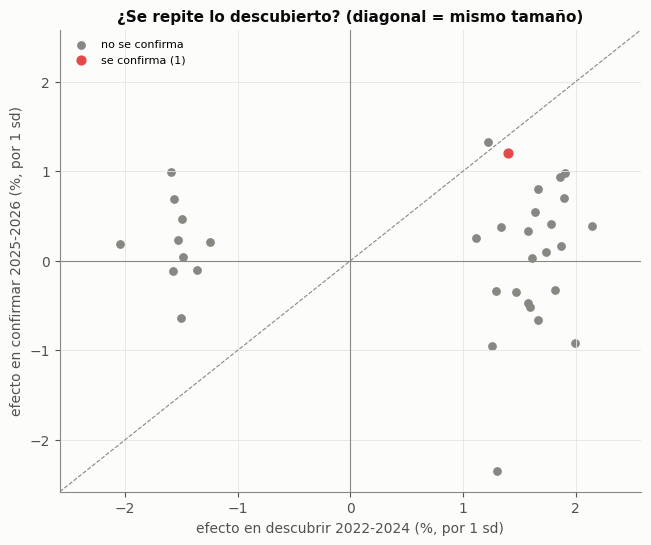

In [9]:
display(C[["variable", "forma", "rezago", "efecto %", "efecto % conf", "p conf", "efecto % con mes fijo 2022-26", "p con mes fijo"]]
        .round({"efecto %": 1, "efecto % conf": 1, "p conf": 4, "efecto % con mes fijo 2022-26": 1, "p con mes fijo": 4}))
fig, ax = plt.subplots(figsize=(7.5, 6))
nc = ~S["confirma (mismo signo, p < 0,05)"]
ax.scatter(S.loc[nc, "efecto %"], S.loc[nc, "efecto % conf"], s=28, color=MUDO, label="no se confirma")
ax.scatter(C["efecto %"], C["efecto % conf"], s=40, color=ROJO, label=f"se confirma ({len(C)})")
lim = np.nanmax(np.abs(S[["efecto %", "efecto % conf"]].values)) * 1.1 if len(S) else 5
ax.plot([-lim, lim], [-lim, lim], color=MUDO, lw=.8, ls="--"); ax.axhline(0, color=MUDO, lw=.8); ax.axvline(0, color=MUDO, lw=.8)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel("efecto en descubrir 2022-2024 (%, por 1 sd)"); ax.set_ylabel("efecto en confirmar 2025-2026 (%, por 1 sd)")
ax.set_title("¿Se repite lo descubierto? (diagonal = mismo tamaño)"); ax.legend(fontsize=8); plt.show()

## Lectura

**No se confirma casi nada, y lo que se confirma es lo que daría el azar.**

| | |
|---|---|
| Sobreviven a BH en descubrir | 34 |
| Mismo signo en confirmar | 18 (la mitad: una moneda) |
| **Confirman (mismo signo, p < 0,05)** | **1** |
| Confirman con BH en la familia de confirmación | **0** |
| Confirmaciones esperadas si **todo** fuera real | ~18 (potencia mediana 0,49) |
| Confirmaciones esperadas si **nada** fuera real | 0,85 |

- **El efecto en confirmar es, en mediana, el 4 % del de descubrir.** Casi todo lo descubierto era
  del periodo 2022-2024, no del clima.
- **No es falta de datos.** Con la potencia calculada, un efecto real del tamaño descubierto se habría
  repetido la mitad de las veces. **Tampoco es peor medida:** en confirmar hay más días con
  pluviómetro válido (53,2 %) que en descubrir (35,8 %).
- Una prueba **se invierte con significación**: los días con mínima > p90, a 5 semanas, pasan de
  +1,3 % a −2,3 % (p = 0,018).

**La única que se repite: el cambio de radiación a 2 semanas, a rezago 0.** Una semana más soleada que
la de hace dos semanas trae:
- **+1,4 % de triage en descubrir y +1,2 % en confirmar** (p = 0,037);
- **+1,0 % con el mes del año fijo en 2022-2026** (p = 0,001). No es solo la estación.

**Pero no pasa BH dentro de la confirmación, y una sola confirmación entre 34 es lo que da el azar
(0,85).** Es un candidato, no un hallazgo.

**Lectura de mecanismo, con cautela.** Es contemporánea y va con el cielo despejado, no con el frío.
Encaja mejor con **acceso** (la lluvia deja a la gente en casa; el cuaderno 11 lo vio en las riñas,
−5,7 %) que con **contagio**, que tendría rezago.

**Límites.**
- La radiación es solo NASA POWER, una celda de ~55 km.
- Para usarla en operación haría falta el **pronóstico** de nubosidad de la semana, no la observación.

---
# 5. Los estados del clima: componentes principales

Se ajustan en las **anomalías semanales** de 10 variables (sin las horas de lluvia, por calidad):
- estandarizadas con la media y la desviación de descubrir;
- **ajustados solo en descubrir** y proyectados sobre todo el resto.

Cada componente se orienta para que su carga mayor sea positiva y se mide en desviaciones típicas de
descubrir.

ajustado en 148 semanas de descubrir; varianza explicada: {'CP1': 51.6, 'CP2': 24.6, 'CP3': 7.6, 'CP4': 6.2} acumulada 90.0 %
semanas proyectadas en confirmar: 85 ; varianza de los índices en confirmar (1 = igual que en descubrir): {'CP1': 0.74, 'CP2': 0.64, 'CP3': 1.45, 'CP4': 1.26}


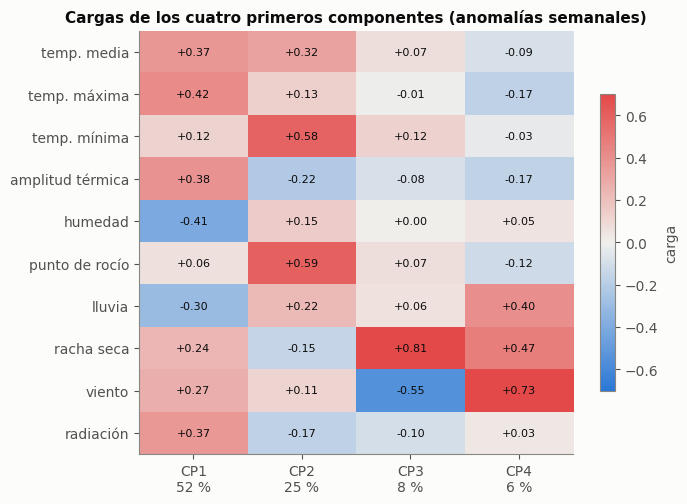

,CP1,CP2,CP3,CP4
temp. media,0.37,0.32,0.07,-0.09
temp. máxima,0.42,0.13,-0.01,-0.17
temp. mínima,0.12,0.58,0.12,-0.03
amplitud térmica,0.38,-0.22,-0.08,-0.17
humedad,-0.41,0.15,0.00,0.05
punto de rocío,0.06,0.59,0.07,-0.12
lluvia,-0.30,0.22,0.06,0.40
racha seca,0.24,-0.15,0.81,0.47
viento,0.27,0.11,-0.55,0.73
radiación,0.37,-0.17,-0.10,0.03


In [10]:
VARS_PCA = ["temp. media", "temp. máxima", "temp. mínima", "amplitud térmica", "humedad", "punto de rocío", "lluvia", "racha seca", "viento", "radiación"]
A = anom[VARS_PCA]
mu, sd = A.loc[DESC[0]:DESC[1]].mean(), A.loc[DESC[0]:DESC[1]].std()
Z = (A - mu) / sd
ajuste = Z.loc[DESC[0]:DESC[1]].dropna()
pca = PCA(n_components=4).fit(ajuste.values)
cargas = pd.DataFrame(pca.components_.T, index=VARS_PCA, columns=[f"CP{i+1}" for i in range(4)])
signo = np.sign(cargas.apply(lambda c: c[c.abs().idxmax()])); cargas = cargas * signo      # la carga mayor, positiva
completas = Z.dropna()
IDX = pd.DataFrame(pca.transform(completas.values) * signo.values, index=completas.index, columns=cargas.columns).reindex(SEM)
IDX = IDX / IDX.loc[DESC[0]:DESC[1]].std()             # en desviaciones típicas de descubrir
print(f"ajustado en {len(ajuste)} semanas de descubrir; varianza explicada:",
      dict(zip(cargas.columns, (100 * pca.explained_variance_ratio_).round(1))), f"acumulada {100 * pca.explained_variance_ratio_.sum():.1f} %")
print("semanas proyectadas en confirmar:", IDX.loc[CONF[0]:CONF[1]].notna().all(axis=1).sum(),
      "; varianza de los índices en confirmar (1 = igual que en descubrir):", IDX.loc[CONF[0]:CONF[1]].var().round(2).to_dict())
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(cargas.values, cmap=DIVERGENTE, vmin=-.7, vmax=.7, aspect="auto")
for i in range(cargas.shape[0]):
    for j in range(cargas.shape[1]):
        ax.text(j, i, f"{cargas.values[i, j]:+.2f}", ha="center", va="center", fontsize=8, color=TINTA)
ax.set_xticks(range(4), [f"{c}\n{100 * r:.0f} %" for c, r in zip(cargas.columns, pca.explained_variance_ratio_)])
ax.set_yticks(range(len(VARS_PCA)), VARS_PCA); ax.grid(False); plt.colorbar(im, ax=ax, shrink=.7, label="carga")
ax.set_title("Cargas de los cuatro primeros componentes (anomalías semanales)"); plt.show()
cargas.round(2)

## Lectura

**Cuatro estados explican el 90,0 % de la varianza de las anomalías semanales** (148 semanas de
descubrir):

| Índice | Varianza | Cargas que lo definen | Qué es |
|---|---|---|---|
| **CP1 soleado y seco** | 51,6 % | máxima +0,42, amplitud +0,38, radiación +0,37, temp. media +0,37; humedad −0,41, lluvia −0,30 | Cielo despejado: días calientes, noches frías, poca lluvia. En negativo, **nublado, húmedo y lluvioso** |
| **CP2 bochorno húmedo** | 24,6 % | punto de rocío +0,59, mínima +0,58, media +0,32, lluvia +0,22 | Aire cargado de humedad y noches templadas |
| **CP3 racha seca en calma** | 7,6 % | racha seca +0,81, viento −0,55 | Días seguidos sin lluvia y sin viento |
| **CP4 ventoso** | 6,2 % | viento +0,73, racha seca +0,47, lluvia +0,40 | Semanas de viento |

**En confirmar, CP1 y CP2 varían menos** que en descubrir (0,74 y 0,64 de la varianza), y **CP3 y CP4
más** (1,45 y 1,26).

**Límite.** CP3 y CP4 cargan sobre la racha seca, que es la variable menos fiable (sección 1). Hay que
leerlos con cautela.

índices: 4 x 9 rezagos = 36 pruebas en descubrir; sobreviven a BH: 1
r entre la curva de descubrir y la de confirmar (9 rezagos): {'CP1 soleado y seco': 0.11, 'CP2 bochorno húmedo': 0.39, 'CP3 racha seca en calma': -0.4, 'CP4 ventoso': 0.01}
en confirmar con p < 0,05: [{'variable': 'CP3 racha seca en calma', 'rezago': 1, 'efecto %': 0.848, 'p': 0.024}]


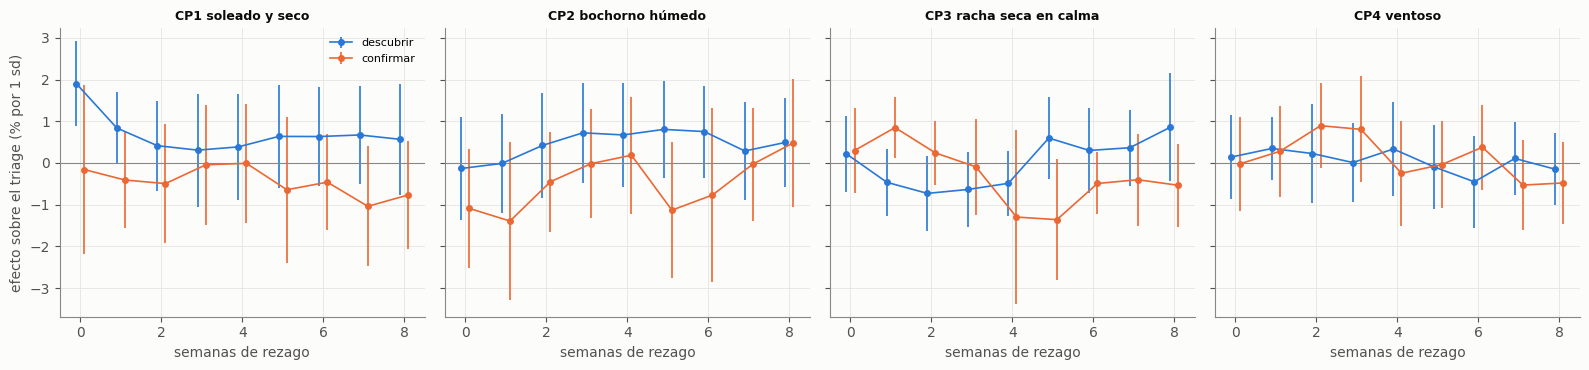

,,efecto % confirmar,efecto % descubrir,p confirmar,p descubrir,sobrevive BH
variable,rezago,,,,,
CP1 soleado y seco,0,-0.1593,1.8996,0.8778,0.0003,True


In [11]:
NOMBRES_CP = ['CP1 soleado y seco', 'CP2 bochorno húmedo', 'CP3 racha seca en calma', 'CP4 ventoso']   # leídos de las cargas de arriba
NOMBRES = dict(zip(cargas.columns, NOMBRES_CP))
IDX = IDX.rename(columns=NOMBRES)
PI = pd.concat([barrer(IDX, Y.y, DESC).assign(periodo="descubrir"), barrer(IDX, Y.y, CONF).assign(periodo="confirmar")], ignore_index=True)
PI["efecto %"] = pct(PI.b)
d = PI.periodo.eq("descubrir")
PI.loc[d, "sobrevive BH"] = multipletests(PI.loc[d, "p"].fillna(1), alpha=Q_BH, method="fdr_bh")[0]
print(f"índices: {IDX.shape[1]} x {len(REZAGOS)} rezagos = {d.sum()} pruebas en descubrir; sobreviven a BH: {int(PI.loc[d, 'sobrevive BH'].sum())}")
cur = PI.pivot_table(index=["variable", "rezago"], columns="periodo", values="efecto %")
print("r entre la curva de descubrir y la de confirmar (9 rezagos):", cur.groupby(level=0).apply(lambda g: round(g.descubrir.corr(g.confirmar), 2)).to_dict())
print("en confirmar con p < 0,05:", PI[(PI.periodo == "confirmar") & (PI.p < .05)][["variable", "rezago", "efecto %", "p"]].round(3).to_dict("records"))
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, c in zip(axes, IDX.columns):
    for per, col in [("descubrir", AZUL), ("confirmar", NARANJA)]:
        q = PI[(PI.variable == c) & (PI.periodo == per)]
        ax.errorbar(q.rezago + (.1 if per == "confirmar" else -.1), q["efecto %"], yerr=1.96 * 100 * q.se, fmt="o-", ms=4, lw=1.2, color=col, label=per)
    ax.axhline(0, color=MUDO, lw=.8); ax.set_title(c, fontsize=9); ax.set_xlabel("semanas de rezago")
axes[0].set_ylabel("efecto sobre el triage (% por 1 sd)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
w = PI.pivot_table(index=["variable", "rezago"], columns="periodo", values=["efecto %", "p"]).round(4)
w.columns = [f"{a} {b}" for a, b in w.columns]
w = w.join(PI[d].set_index(["variable", "rezago"])["sobrevive BH"])
w[w["p descubrir"] < .05]

## Lectura

**Los estados del clima no se sostienen contra el triage total.**
- De 36 pruebas en descubrir (4 índices × 9 rezagos), **sobrevive una: CP1 soleado y seco a rezago
  0**, +1,9 % por sd (p = 0,0003).
- **En confirmar da −0,16 % (p = 0,88).** No se confirma.

Es la misma señal contemporánea de la sección 3, resumida en un índice, y corre la misma suerte.

La figura muestra el porqué:
- **las curvas de descubrir (azul) y de confirmar (naranja) no se parecen.** Su correlación a lo
  largo de los 9 rezagos es 0,11 en CP1, 0,39 en CP2, −0,40 en CP3 y 0,01 en CP4;
- en confirmar, solo una prueba da p < 0,05: **CP3 a 1 semana, +0,85 % (p = 0,024)**. No es ninguna
  que se hubiera descubierto, y entre 36 pruebas es lo que da el azar.

**Para el triage total, los estados del clima describen la ciudad, pero no predicen su demanda.**

---
# 6. Los desenlaces secundarios: donde el clima debería pesar más

`CLAUDE.md` argumenta que probar el clima sobre el total es la peor elección por **dilución**: si lo
respiratorio es una fracción pequeña del triage, un efecto grande sobre ella es invisible en el total.

Aquí se repite el barrido **de los índices, no de las 77 variables**, contra tres series de diagnóstico
del cuaderno 10:
- respiratorio;
- infecciosas;
- trauma.

Van con el mismo tratamiento del desenlace. Los índices son los 4 estados del clima y las 4 variables
de temporada. **BH sobre las 216 pruebas juntas.**

3 desenlaces x 8 índices x 9 rezagos = 216 pruebas; sobreviven a BH en descubrir: 0; se confirman: 0
sd semanal de cada desenlace en descubrir (log): {'y': 0.061, 'y_respiratorio': 0.321, 'y_infecciosas': 0.366, 'y_trauma': 0.168}
casos por semana en descubrir: {'triage': 1430, 'Respiratorio': 49.1, 'Infecciosas': 35.5, 'Traumatismos': 83.4}


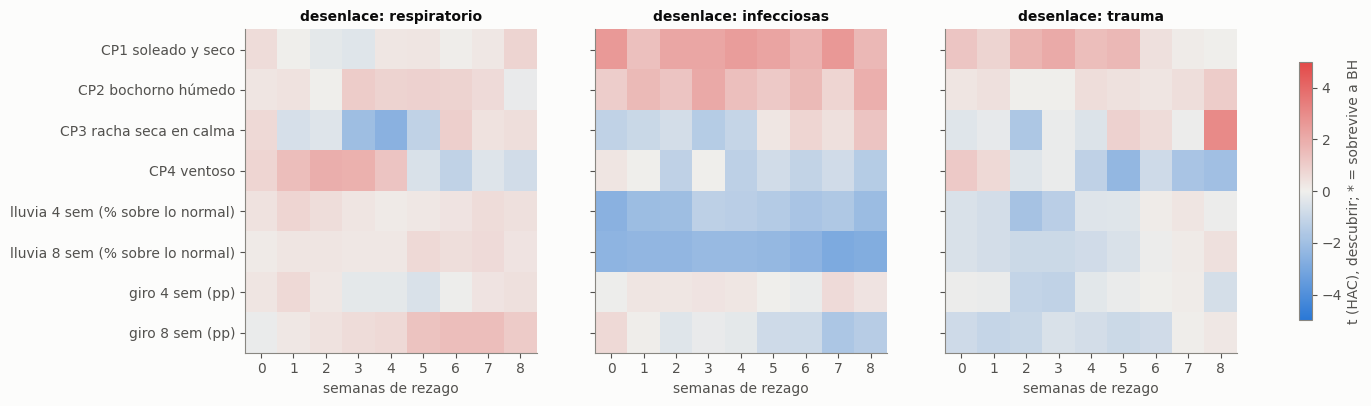

Las 3 pruebas más fuertes de cada desenlace (sobrevivan o no):


,desenlace,variable,rezago,efecto %,p,q,sobrevive BH,efecto % conf,p conf,confirma
196,y_infecciosas,lluvia 8 sem (% sobre lo normal),7,-13.4,0.00425,0.309,False,7.3,0.2229,False
197,y_infecciosas,lluvia 8 sem (% sobre lo normal),8,-12.8,0.00568,0.309,False,1.5,0.7553,False
151,y_infecciosas,CP1 soleado y seco,7,11.0,0.00924,0.309,False,-5.9,0.2262,False
22,y_respiratorio,CP3 racha seca en calma,4,-4.9,0.01072,0.309,False,-0.1,0.9621,False
21,y_respiratorio,CP3 racha seca en calma,3,-3.9,0.03898,0.359,False,1.4,0.4875,False
29,y_respiratorio,CP4 ventoso,2,4.5,0.05154,0.412,False,4.4,0.0775,False
314,y_trauma,CP3 racha seca en calma,8,4.4,0.00263,0.309,False,-0.3,0.9135,False
320,y_trauma,CP4 ventoso,5,-3.3,0.02008,0.329,False,-1.1,0.5582,False
291,y_trauma,CP1 soleado y seco,3,2.9,0.04211,0.364,False,-2.4,0.1952,False


In [12]:
SEC = [c for c in ["y_respiratorio", "y_infecciosas", "y_trauma"] if c in Y]
IND = pd.concat([IDX, TEMP], axis=1)
IND = IND / IND.loc[DESC[0]:DESC[1]].std()
P2 = []
for s in SEC:
    P2 += [barrer(IND, Y[s], DESC).assign(desenlace=s, periodo="descubrir"), barrer(IND, Y[s], CONF).assign(desenlace=s, periodo="confirmar")]
P2 = pd.concat(P2, ignore_index=True); P2["efecto %"] = pct(P2.b)
dd = P2[P2.periodo.eq("descubrir")].copy()
dd["sobrevive BH"], dd["q"], *_ = multipletests(dd.p.fillna(1), alpha=Q_BH, method="fdr_bh")
cc = P2[P2.periodo.eq("confirmar")].set_index(["desenlace", "variable", "rezago"])[["efecto %", "p"]].add_suffix(" conf")
dd = dd.join(cc, on=["desenlace", "variable", "rezago"])
dd["confirma"] = dd["sobrevive BH"] & (np.sign(dd["efecto %"]) == np.sign(dd["efecto % conf"])) & (dd["p conf"] < .05)
print(f"{len(SEC)} desenlaces x {IND.shape[1]} índices x {len(REZAGOS)} rezagos = {len(dd)} pruebas; sobreviven a BH en descubrir: "
      f"{int(dd['sobrevive BH'].sum())}; se confirman: {int(dd.confirma.sum())}")
print("sd semanal de cada desenlace en descubrir (log):", {s: round(Y[s].loc[DESC[0]:DESC[1]].std(), 3) for s in ["y"] + SEC})
dx = pd.read_parquet(RAIZ / "salidas/perfil_dx_diario.parquet"); dx["dia"] = pd.to_datetime(dx["dia"])
dx = dx[dx.dia.between("2022-03-06", "2024-12-28")]
print("casos por semana en descubrir:", {"triage": round(Y.triage.loc[DESC[0]:DESC[1]].mean()),
      **{c.split(" ")[1]: round(dx[dx.capitulo.eq(c)].n.sum() / (len(pd.date_range("2022-03-06", "2024-12-28")) / 7), 1)
         for c in ["X Respiratorio", "I Infecciosas y parasitarias", "XIX Traumatismos y envenenamientos"]}})
fig, axes = plt.subplots(1, len(SEC), figsize=(16, 4.2), sharey=True)
for ax, s in zip(np.atleast_1d(axes), SEC):
    q = dd[dd.desenlace.eq(s)].assign(t=lambda x: x.b / x.se).pivot(index="variable", columns="rezago", values="t").reindex(IND.columns)
    im = ax.imshow(q.values, cmap=DIVERGENTE, vmin=-5, vmax=5, aspect="auto")
    for (i, v_), (j, k) in [((i, v_), (j, k)) for i, v_ in enumerate(q.index) for j, k in enumerate(q.columns)]:
        if dd[(dd.desenlace == s) & (dd.variable == v_) & (dd.rezago == k)]["sobrevive BH"].any():
            ax.text(j, i, "*", ha="center", va="center", fontsize=11, color=TINTA)
    ax.set_xticks(range(len(q.columns)), q.columns); ax.set_xlabel("semanas de rezago"); ax.set_title(s.replace("y_", "desenlace: "), fontsize=10); ax.grid(False)
np.atleast_1d(axes)[0].set_yticks(range(IND.shape[1]), IND.columns)
plt.colorbar(im, ax=axes, shrink=.8, label="t (HAC), descubrir; * = sobrevive a BH")
plt.show()
print("Las 3 pruebas más fuertes de cada desenlace (sobrevivan o no):")
dd.sort_values("p").groupby("desenlace").head(3)[["desenlace", "variable", "rezago", "efecto %", "p", "q", "sobrevive BH", "efecto % conf", "p conf", "confirma"]] \
  .sort_values(["desenlace", "p"]).round({"efecto %": 1, "efecto % conf": 1, "p": 5, "q": 3, "p conf": 4})

## Lectura

**Nada sobrevive: 0 de 216.** La prueba más fuerte de cada serie:

| Desenlace | Índice | Rezago | Descubrir | q | Confirmar |
|---|---|---|---|---|---|
| Infecciosas | lluvia de 8 semanas | 7 | −13,4 % (p = 0,004) | 0,31 | **+7,3 %** |
| Respiratorio | CP3 racha seca en calma | 4 | −4,9 % (p = 0,011) | 0,31 | −0,1 % |
| Trauma | CP3 racha seca en calma | 8 | +4,4 % (p = 0,003) | 0,31 | −0,3 % |

Ninguna llega a q = 0,10, y ninguna repite en confirmar.

**Por qué la dilución no se resolvió aquí: la serie específica es mucho más ruidosa.** Desviación
típica semanal del log en descubrir:

| Serie | Casos por semana | Desviación típica |
|---|---|---|
| Triage total | 1.430 | **0,061** |
| Respiratorio | 49,1 | **0,321** |
| Infecciosas | 35,5 | 0,366 |
| Trauma | 83,4 | 0,168 |

- Con ~49 casos por semana, solo el azar de conteo ya pone ~14 % de ruido (1/√49).
- El resto es la forma de las olas respiratorias, que el desenlace conserva.
- **El efecto sube, pero el ruido sube cinco veces más.** Los efectos respiratorios que se ven (−4,9 %
  por sd) son mayores que los del total (1-2 %), pero la relación señal/ruido no mejora.

**Límites.**
- Las series de diagnóstico son las del **egreso** del cuaderno 10 (capítulo CIE-10), no el motivo de
  triage.
- No se probó la **IRA de la ciudad** (SIVIGILA). El cuaderno 11 sí encontró frío y humedad del último
  mes → IRA de la ciudad (+8-10 %). **El puente clima → ciudad existe; el puente ciudad → este hospital,
  semana a semana, no aparece en estos datos.**

---
# 7. El horizonte largo: cómo está hoy el clima y qué hicieron episodios parecidos

Primero, las últimas semanas con clima completo (el archivo termina el 2026-08-28) en los índices y en
la temporada. Después, la lluvia mensual del último año contra lo normal, con dos controles:
- **NASA sin escalar**: su anomalía contra su propia normal, independiente del pluviómetro;
- **el % de días con pluviómetro válido**.

**Esto es descriptivo, no un pronóstico.**

In [13]:
ACT = pd.concat([IDX, TEMP.round(0), anom["temp. media"].rename("temp. media, anomalía (°C)"),
                 nivel["racha seca"].rename("racha seca al cierre (días)")], axis=1).loc["2026-05-03":"2026-08-23"].round(2)
ACT.index = ACT.index.strftime("%Y-%m-%d"); ACT.index.name = "semana que empieza"
print("rango de cada índice en descubrir (sd):", {c: (round(IDX[c].loc[DESC[0]:DESC[1]].min(), 2), round(IDX[c].loc[DESC[0]:DESC[1]].max(), 2)) for c in IDX})
print("racha seca al cierre de semana, máximo en descubrir:", nivel["racha seca"].loc[DESC[0]:DESC[1]].max(), "días")
display(ACT)
mm = diarias.lluvia.loc["2025-09-01":"2026-08-28"].resample("MS").sum()
normal_mes = diarias.lluvia.loc[CLIMA_REF[0]:CLIMA_REF[1]]; normal_mes = normal_mes.groupby(normal_mes.index.month).mean()
fuente = (dia.precip_con_estacion & ~dia.pluviometro_fallido).loc["2025-09-01":"2026-08-28"].resample("MS").mean()
nasa_mm = dia.np_PRECTOTCORR.loc["2025-09-01":"2026-08-28"].resample("MS").sum()          # control independiente del pluviómetro
nasa_ref = dia.np_PRECTOTCORR.loc[CLIMA_REF[0]:CLIMA_REF[1]]; nasa_ref = nasa_ref.groupby(nasa_ref.index.month).mean()
pd.DataFrame({"lluvia (mm)": mm.round(0), "NASA sin escalar, % sobre su propia normal":
              (100 * (nasa_mm / (nasa_ref.reindex(nasa_mm.index.month).values * nasa_mm.index.days_in_month) - 1)).round(0),"normal (mm)": (normal_mes.reindex(mm.index.month).values * mm.index.days_in_month).round(0),
              "% sobre lo normal": (100 * (mm / (normal_mes.reindex(mm.index.month).values * mm.index.days_in_month) - 1)).round(0),
              "% días con pluviómetro": (100 * fuente).round(0)}).set_axis(mm.index.strftime("%Y-%m")).T

rango de cada índice en descubrir (sd): {'CP1 soleado y seco': (-2.2, 3.02), 'CP2 bochorno húmedo': (-3.63, 2.4), 'CP3 racha seca en calma': (-2.08, 4.96), 'CP4 ventoso': (-2.18, 2.88)}
racha seca al cierre de semana, máximo en descubrir: 15.0 días


,CP1 soleado y seco,CP2 bochorno húmedo,CP3 racha seca en calma,CP4 ventoso,lluvia 4 sem (% sobre lo normal),lluvia 8 sem (% sobre lo normal),giro 4 sem (pp),giro 8 sem (pp),"temp. media, anomalía (°C)",racha seca al cierre (días)
semana que empieza,,,,,,,,,,
2026-05-03,0.66,-0.39,0.60,-1.62,-28.0,-28.0,1.0,-42.0,0.35,1.0
2026-05-10,0.42,-0.10,1.11,-2.17,-45.0,-29.0,-28.0,-43.0,0.44,1.0
2026-05-17,0.40,-0.35,0.42,-2.35,-52.0,-39.0,-22.0,-55.0,0.39,0.0
2026-05-24,-0.13,0.86,1.49,-2.61,-46.0,-43.0,-5.0,-28.0,0.56,0.0
2026-05-31,-0.09,1.07,1.25,-1.93,-58.0,-43.0,-29.0,-26.0,0.53,0.0
2026-06-07,0.48,0.25,0.63,-1.70,-50.0,-47.0,-6.0,-34.0,0.44,0.0
2026-06-14,0.31,-0.12,0.71,-1.41,-28.0,-39.0,24.0,-23.0,0.34,0.0
2026-06-21,1.19,0.58,0.79,0.69,-2.0,-22.0,44.0,5.0,1.14,2.0
2026-06-28,-0.26,1.32,1.40,-2.00,24.0,-22.0,82.0,6.0,0.78,0.0


fecha,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
lluvia (mm),57.0,146.0,69.0,46.0,187.0,91.0,153.0,81.0,68.0,129.0,55.0,111.0
"NASA sin escalar, % sobre su propia normal",40.0,17.0,-28.0,-29.0,125.0,50.0,-8.0,-35.0,-44.0,-19.0,-49.0,28.0
normal (mm),54.0,139.0,97.0,81.0,80.0,62.0,176.0,126.0,123.0,158.0,115.0,77.0
% sobre lo normal,7.0,5.0,-29.0,-42.0,132.0,46.0,-13.0,-35.0,-45.0,-19.0,-52.0,44.0
% días con pluviómetro,90.0,35.0,100.0,100.0,16.0,0.0,0.0,0.0,0.0,0.0,52.0,43.0


episodios de fin de sequía 2020-2026: ['2020-11-15', '2021-01-17', '2021-06-13', '2021-11-28', '2024-04-21', '2025-10-05', '2026-01-11', '2026-06-28']
semanas de 2026 que cumplen la regla: ['2026-01-11', '2026-01-18', '2026-01-25', '2026-02-01', '2026-06-28', '2026-07-05', '2026-08-16']


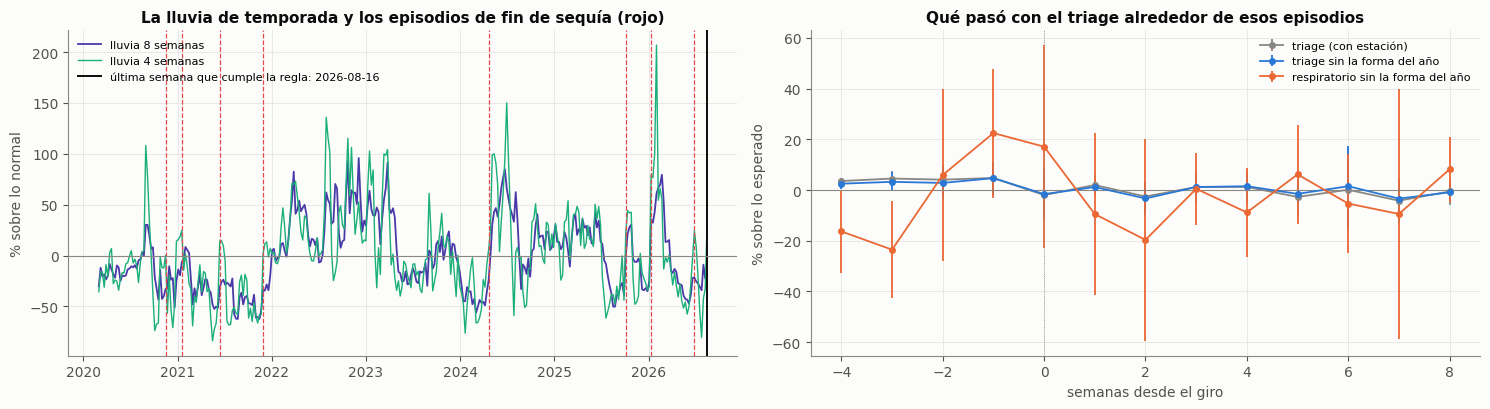

,episodios con triage,semanas −4 a −1,semanas 0 a 3,semanas 4 a 8,"sd entre episodios, 4 a 8"
serie,,,,,
triage (con estación),4,4.2,-0.4,-1.3,7.0
triage sin la forma del año,4,3.3,-0.7,-0.6,4.7
respiratorio sin la forma del año,4,-4.5,-3.8,-2.1,12.7


In [14]:
# Episodios parecidos al de hoy, regla fijada antes de mirar el triage: 8 semanas previas secas y giro a lluvioso.
UMBRAL_SECO, UMBRAL_HUMEDO = -25, 0     # % sobre lo normal: 8 semanas (hasta hace 4) al menos 25 % bajo lo normal; últimas 4 semanas en lo normal o más
seco_previo = TEMP["lluvia 8 sem (% sobre lo normal)"].shift(4) <= UMBRAL_SECO
giro = TEMP["lluvia 4 sem (% sobre lo normal)"] >= UMBRAL_HUMEDO
marca = (seco_previo & giro)
inicio = marca & ~marca.shift(1, fill_value=False).rolling(8, min_periods=1).max().astype(bool)   # un episodio cada 8 semanas como mínimo
EPIS = list(marca[inicio].index)
print("episodios de fin de sequía 2020-2026:", [f"{e:%Y-%m-%d}" for e in EPIS])
print("semanas de 2026 que cumplen la regla:", [f"{e:%Y-%m-%d}" for e in marca[marca].loc["2026"].index])
ys = Y.y - Y.y.groupby((Y.index + pd.Timedelta(days=3)).month).transform("mean")    # sin la forma del año (descriptivo)
K = range(-4, 9)
filas, curvas = [], {}
for nom, serie in [("triage (con estación)", Y.y), ("triage sin la forma del año", ys)] + \
                  ([("respiratorio sin la forma del año", Y.y_respiratorio - Y.y_respiratorio.groupby((Y.index + pd.Timedelta(days=3)).month).transform("mean"))] if "y_respiratorio" in Y else []):
    Mx = pd.DataFrame({e: [serie.get(e + pd.Timedelta(weeks=k), np.nan) for k in K] for e in EPIS if e >= pd.Timestamp("2022-03-06")}, index=list(K))
    curvas[nom] = Mx
    filas.append({"serie": nom, "episodios con triage": int(Mx.notna().any().sum()),
                  "semanas −4 a −1": round(pct(Mx.loc[-4:-1].stack().mean()), 1),
                  "semanas 0 a 3": round(pct(Mx.loc[0:3].stack().mean()), 1),
                  "semanas 4 a 8": round(pct(Mx.loc[4:8].stack().mean()), 1),
                  "sd entre episodios, 4 a 8": round(100 * Mx.loc[4:8].mean().std(), 1)})
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
ax = axes[0]; w = SEM[SEM >= "2020-03-01"]
ax.plot(w, TEMP.loc[w, "lluvia 8 sem (% sobre lo normal)"], color=VIOLETA, lw=1.3, label="lluvia 8 semanas")
ax.plot(w, TEMP.loc[w, "lluvia 4 sem (% sobre lo normal)"], color=AQUA, lw=1, label="lluvia 4 semanas")
for e in EPIS: ax.axvline(e, color=ROJO, lw=.9, ls="--")
ultima = marca[marca].index.max()
ax.axvline(ultima, color=TINTA, lw=1.4, label=f"última semana que cumple la regla: {ultima:%Y-%m-%d}")
ax.axhline(0, color=MUDO, lw=.8); ax.set_ylabel("% sobre lo normal"); ax.legend(fontsize=8, loc="upper left")
ax.set_title("La lluvia de temporada y los episodios de fin de sequía (rojo)")
ax = axes[1]
for (nom, Mx), col in zip(curvas.items(), [MUDO, AZUL, NARANJA]):
    m = Mx.mean(axis=1); e = 1.96 * Mx.std(axis=1) / np.sqrt(Mx.notna().sum(axis=1))
    ax.errorbar(np.array(list(K)), pct(m), yerr=100 * e, fmt="o-", ms=4, lw=1.3, color=col, label=nom)
ax.axhline(0, color=MUDO, lw=.8); ax.axvline(0, color=MUDO, lw=.6, ls=":")
ax.set_xlabel("semanas desde el giro"); ax.set_ylabel("% sobre lo esperado"); ax.legend(fontsize=8)
ax.set_title("Qué pasó con el triage alrededor de esos episodios"); plt.tight_layout(); plt.show()
pd.DataFrame(filas).set_index("serie")

## Lectura

**La sequía de 2026 es real, y está terminando en agosto.** Lluvia del consenso frente a lo normal del
mes:

| | mar | abr | may | jun | jul | **ago** |
|---|---|---|---|---|---|---|
| Consenso | −13 % | −35 % | −45 % | −19 % | **−52 %** | **+44 %** |
| NASA sin escalar | −8 % | −35 % | −44 % | −19 % | −49 % | +28 % |
| Días con pluviómetro | 0 % | 0 % | 0 % | 0 % | 52 % | 43 % |

- **De marzo a junio no hubo ni un día de pluviómetro** (la falla de La Nubia). Aun así, NASA sin
  escalar da la misma sequía, así que **no es la sequía falsa** que fabricaba el pluviómetro roto
  (`CLIMA.md`).
- Julio fue el mes más seco de 2026, con una racha de **14 días sin lluvia** al cierre de la semana
  del 2026-07-12 (el máximo en descubrir fue 15). Con el viento en calma, CP3 marca **7,17 sd**, muy
  por encima de su máximo en descubrir (4,96).
- **En agosto gira.** La lluvia de 4 semanas pasa de −80 % (semana del 2026-07-26) a **+30 %** (semana
  del 2026-08-16). Es un giro de **+86 puntos**, mientras la de 8 semanas sigue en −17 %.
- **Además hace calor.** La temperatura media va **+1,0 a +1,3 °C** sobre lo normal en las semanas del
  9 y el 16 de agosto. La semana del 16 marca **2,80 sd en CP2 bochorno húmedo**, por encima de su máximo en descubrir
  (2,40).

**Hoy: fin de sequía, cálido y húmedo.** Con la regla fijada antes de mirar el triage (8 semanas, hasta
hace 4, al menos un 25 % bajo lo normal, y las últimas 4 en lo normal o más), la semana del
**2026-08-16 cumple el criterio**. La del 2026-06-28 fue una falsa salida: julio volvió a secarse.

**Qué hicieron los episodios parecidos.**
- La regla marca 8 episodios desde 2020, **4 con triage**: 2024-04-21, 2025-10-05, 2026-01-11 y
  2026-06-28.
- **En las 4-8 semanas siguientes, el triage sin la forma del año quedó en −0,6 %**, con una
  desviación entre episodios de 4,7 puntos. Con la estación incluida, −1,3 %.
- **El respiratorio, en −2,1 %**, con una desviación de 12,7 puntos.

**No hay ola después del fin de la sequía.** Con cuatro episodios no se puede afirmar que no la haya,
pero no hay nada que anunciar.

**Límites.**
- 4 episodios es anecdótico; la figura lo muestra con intervalos que cruzan el cero en todo.
- Uno de los 4 (2026-06-28) se solapa con el episodio actual.
- La serie de 2026 de marzo a junio es reanálisis escalado, no medida en tierra.
- El desenlace está limpio de los escalones de la red, pero **el nivel de 2026 lo mueve Nueva EPS**
  (cuaderno 07). Cualquier efecto del clima tendría que verse por encima de eso.

---
# 8. Qué entra al repertorio y qué no

**Balance del barrido:**
- 693 pruebas del clima completo: 34 sobreviven a BH en descubrir y **1 se confirma**. Es lo que
  daría el azar (0,85).
- 36 pruebas de los estados del clima: **0 confirmadas**.
- 216 pruebas de índices contra respiratorio, infecciosas y trauma: **0 sobreviven**.

**La respuesta al propietario es honesta y es negativa: el clima completo no mueve el triage total de
este hospital semana a semana, ni a 0-8 semanas, de forma que se repita.** La señal de 2022-2024
(semanas soleadas y secas, +1-2 % por sd) no volvió en 2025-2026.

Tampoco es falta de potencia: con los datos de confirmar, un efecto así se habría visto la mitad de
las veces. **Haberlo metido todo al modelo habría sido exactamente el sobreajuste que preocupa.**

| Pieza | Decisión | Por qué |
|---|---|---|
| **Cambio de radiación a 2 semanas** (rezago 0) | **Entra a prueba**, como único candidato del clima | La única que se repite (+1,4 % → +1,2 % por sd), también con el mes fijo. Pero no pasa BH en la confirmación: **sale si no mejora el control de calendario con origen rodante**. En operación necesita el pronóstico de nubosidad |
| **CP1 soleado y seco** y **CP2 bochorno húmedo** | **Contexto**: describen el estado de la ciudad en dos números | Resumen el 76 % del clima semanal. No predicen el triage (CP1 no se confirma: −0,16 %) |
| **Fin de sequía** (lluvia de 4 y 8 semanas y su giro) | **Contexto**: se sigue, no se usa para predecir | No sobrevive en descubrir, y los 4 episodios con triage no muestran ola (−0,6 % a 4-8 semanas) |
| Frío y humedad del último mes (cuaderno 11) | **Se queda como está**: explica la IRA de la **ciudad** | Aquí no aparece en el hospital: ni CP2 ni las temperaturas se confirman contra respiratorio |
| CP3 y CP4, racha seca, extremos, horas de lluvia, las 77 variables sueltas | **No entran** | O no se confirman, o están mal medidas (horas de lluvia r = 0,18; racha seca dependiente de la fuente) |

**Qué queda abierto y no se resuelve con más barrido:**
1. **El puente ciudad → hospital.** El clima mueve la IRA de la ciudad (cuaderno 11), pero no el
   triage de este hospital. El siguiente paso lógico es el cuaderno 13, la vigilancia: si la presión
   epidemiológica de la ciudad sí llega al hospital, el clima entra **a través de ella**, no
   directamente.
2. **El nivel lo mueve la red.** Con el nivel sacado, el clima es un efecto de segundo orden. Esto es
   coherente con la literatura (2-10 %) y con un residuo semanal del 6 %.
3. **La observación frente al pronóstico.** Lo único candidato es contemporáneo: sin el pronóstico
   del tiempo, no sirve para predecir.